# IMPORT PACKAGES

In [1]:
# based on code from Zander at:
# A:\Modeling\Claims\Resource Capacity\Property Adjuster\Report\Score Code\2. Text Mining and Scoring.ipynb
# text mining portion in the above not needed

# LOAD IN LIBRARIES
import pandas as pd
import numpy as np
import re
import ast
# machine learning & metrics
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfTransformer, TfidfVectorizer, CountVectorizer
import catboost as cb
from catboost.utils import eval_metric
import matplotlib.pyplot as plt
import shap
# ENABLE JAVASCRIPT
shap.initjs()

# wordcloud
#import re
#import multidict as multidict
#from wordcloud import WordCloud
#from nltk.tokenize import word_tokenize
#from nltk.corpus import stopwords
#from nltk.corpus import wordnet
#from nltk.stem import WordNetLemmatizer

# wordcloud resources
#import nltk
#nltk.download('stopwords')
#nltk.download('punkt')
#nltk.download('wordnet')

#warnings.filterwarnings('ignore')
pd.options.display.max_rows = 100
pd.options.display.max_columns = 100
pd.options.display.max_colwidth = 200

In [2]:
# Update Date
date="05292024"

# SCORE DATASET

In [4]:
# LOAD IN DATSET
#df1 = pd.read_csv('A:\Modeling\Claims\Resource Capacity\Workers Comp Adjuster\Data\WC_WPC_for_scoring_' + date + '.csv')
df1 = pd.read_csv(r'A:\Share\Claims\WPC\TESTING 2\Workers Comp\2024\05-29-2024\WC_WPC_for_scoring_' + date + '.csv')
#WC_WPC_for_scoring_05292024
df1.head()

,CLM_NR,TOTAL_TOUCHES,AGE_CURR,BMI,FRTH_TRTMT_REQR,INCID_RPT_ONLY,INJ_PRMIS,INJ_REG_JOB,ISS_INVOLVE,JURIS_STATE_PA,JURIS_STATE_VA,JURIS_STATE_MD,JURIS_STATE_NY,JURIS_STATE_WV,JURIS_STATE_WI,JURIS_STATE_NC,JURIS_STATE_TN,JURIS_STATE_IL,JURIS_STATE_IN,JURIS_STATE_WASHDC,LEGAL_IND,LOSS_CAUSE_FALLSLIPTRIP,LOSS_CAUSE_CUTSCRAPE,LOSS_CAUSE_STRAIN,LOSS_CAUSE_VEH,CORP_REFL_PRLYS,INSD_PNL_EXST,PRIOR_TRTMT_EXST,NCCI_INJ_TYP_MEDONLY,NCCI_INJ_TYP_TEMPORARYINJ,NCCI_INJ_TYP_PERMPARTIAL,NCCI_INJ_TYP_PERMTOTAL,NCCI_LOSS_TYP_TRAUMA,NCCI_LOSS_TYP_CUMULATIVE,VCTNL_RHAB_INCL_INDEM,MECH_DFCT_INVLV,PHYS_RSTRC,PRIM_BODY_PART_TRUNK,PRIM_BODY_PART_MULTIPLE,PRIM_BODY_PART_NECKHEAD,MIDDLE_MARKET,ClaimKey,AdjNu,Status,Adj_Team,Adjuster_Work_Group,PayPeriodEnd
0,000100037018,515,77,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,000100037018T5726,T5726,Completed,WC NE-PA,Workers Comp Adjuster,20220713
1,000100071611,50,88,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,000100071611Workers Comp Specialist,M0745,Completed,WC NE-PA,Workers Comp Specialist,20240515
2,000110190270,401,69,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,000110190270M0745,M0745,Completed,WC NE-PA,Workers Comp Specialist,20221019
3,000110319161,325,81,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,000110319161B7419,B7419,Completed,WC NE-PA,Sr Workers Comp Adjuster,20220209
4,000150068865,181,72,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,000150068865D209A,D209A,Completed,WC NE-PA,Sr Workers Comp Adjuster,20221214


In [5]:
# create key field to index and merge on shap results
df1['KeyField'] = df1['CLM_NR'].astype(str) +"-"+ df1['AdjNu'].astype(str) +"-"+ df1['Adj_Team'].astype(str) +"-"+ df1['Status'].astype(str) +"-"+ df1['PayPeriodEnd'].astype(str)  


In [6]:
df1.set_index(['KeyField'], inplace=True)
df1.head()

,CLM_NR,TOTAL_TOUCHES,AGE_CURR,BMI,FRTH_TRTMT_REQR,INCID_RPT_ONLY,INJ_PRMIS,INJ_REG_JOB,ISS_INVOLVE,JURIS_STATE_PA,JURIS_STATE_VA,JURIS_STATE_MD,JURIS_STATE_NY,JURIS_STATE_WV,JURIS_STATE_WI,JURIS_STATE_NC,JURIS_STATE_TN,JURIS_STATE_IL,JURIS_STATE_IN,JURIS_STATE_WASHDC,LEGAL_IND,LOSS_CAUSE_FALLSLIPTRIP,LOSS_CAUSE_CUTSCRAPE,LOSS_CAUSE_STRAIN,LOSS_CAUSE_VEH,CORP_REFL_PRLYS,INSD_PNL_EXST,PRIOR_TRTMT_EXST,NCCI_INJ_TYP_MEDONLY,NCCI_INJ_TYP_TEMPORARYINJ,NCCI_INJ_TYP_PERMPARTIAL,NCCI_INJ_TYP_PERMTOTAL,NCCI_LOSS_TYP_TRAUMA,NCCI_LOSS_TYP_CUMULATIVE,VCTNL_RHAB_INCL_INDEM,MECH_DFCT_INVLV,PHYS_RSTRC,PRIM_BODY_PART_TRUNK,PRIM_BODY_PART_MULTIPLE,PRIM_BODY_PART_NECKHEAD,MIDDLE_MARKET,ClaimKey,AdjNu,Status,Adj_Team,Adjuster_Work_Group,PayPeriodEnd
KeyField,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
000100037018-T5726-WC NE-PA-Completed-20220713,000100037018,515,77,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,000100037018T5726,T5726,Completed,WC NE-PA,Workers Comp Adjuster,20220713
000100071611-M0745-WC NE-PA-Completed-20240515,000100071611,50,88,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,000100071611Workers Comp Specialist,M0745,Completed,WC NE-PA,Workers Comp Specialist,20240515
000110190270-M0745-WC NE-PA-Completed-20221019,000110190270,401,69,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,000110190270M0745,M0745,Completed,WC NE-PA,Workers Comp Specialist,20221019
000110319161-B7419-WC NE-PA-Completed-20220209,000110319161,325,81,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,000110319161B7419,B7419,Completed,WC NE-PA,Sr Workers Comp Adjuster,20220209
000150068865-D209A-WC NE-PA-Completed-20221214,000150068865,181,72,NaN,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,000150068865D209A,D209A,Completed,WC NE-PA,Sr Workers Comp Adjuster,20221214


In [7]:
#scoringdata=df1.merge(detections, on=['SVC_REQ_NR', 'SVC_REQ_NR'])
#scoringdata.drop(['CLAIMDESCRIPTION', 'CLAIMSUMMARY', 'incid_dc', 'note_dc', 'TEXT1'], axis=1, inplace=True)


scoringdata=df1[['FRTH_TRTMT_REQR', 'INCID_RPT_ONLY', 'INJ_PRMIS', 'INJ_REG_JOB', 'ISS_INVOLVE', 'JURIS_STATE_PA', 'JURIS_STATE_VA', 'JURIS_STATE_MD', 'JURIS_STATE_NY', 'JURIS_STATE_WV', 'JURIS_STATE_WI', 'JURIS_STATE_NC', 'JURIS_STATE_TN', 'JURIS_STATE_IL', 'JURIS_STATE_IN', 'JURIS_STATE_WASHDC', 'LEGAL_IND', 'LOSS_CAUSE_FALLSLIPTRIP', 'LOSS_CAUSE_CUTSCRAPE', 'LOSS_CAUSE_STRAIN', 'LOSS_CAUSE_VEH', 'CORP_REFL_PRLYS', 'INSD_PNL_EXST', 'PRIOR_TRTMT_EXST', 'NCCI_INJ_TYP_MEDONLY', 'NCCI_INJ_TYP_TEMPORARYINJ', 'NCCI_INJ_TYP_PERMPARTIAL', 'NCCI_INJ_TYP_PERMTOTAL', 'NCCI_LOSS_TYP_TRAUMA', 'NCCI_LOSS_TYP_CUMULATIVE', 'VCTNL_RHAB_INCL_INDEM', 'MECH_DFCT_INVLV', 'PHYS_RSTRC', 'BMI', 'PRIM_BODY_PART_NECKHEAD', 'PRIM_BODY_PART_TRUNK', 'PRIM_BODY_PART_MULTIPLE', 'MIDDLE_MARKET', 'AGE_CURR', 'TOTAL_TOUCHES']]

#scoringdata['ClaimExpo']= scoringdata[['RPT_BY_DC', 'EXPSR_NTRL_ID']].agg('-'.join, axis=1)
#scoringdata.set_index(['CLM_NTRL_ID','EXPSR_NTRL_ID']).stack().unstack([1,2])
#scoringdata.set_index(['RPT_BY_DC'||'SGMNT_DC']).stack().unstack([1,2])
#scoringdata.set_index(['CLM_NTRL_ID','EXPSR_NTRL_ID'], inplace=True)
#scoringdata.set_index(['ClaimExpo'], inplace=True)
scoringdata.head()

,FRTH_TRTMT_REQR,INCID_RPT_ONLY,INJ_PRMIS,INJ_REG_JOB,ISS_INVOLVE,JURIS_STATE_PA,JURIS_STATE_VA,JURIS_STATE_MD,JURIS_STATE_NY,JURIS_STATE_WV,JURIS_STATE_WI,JURIS_STATE_NC,JURIS_STATE_TN,JURIS_STATE_IL,JURIS_STATE_IN,JURIS_STATE_WASHDC,LEGAL_IND,LOSS_CAUSE_FALLSLIPTRIP,LOSS_CAUSE_CUTSCRAPE,LOSS_CAUSE_STRAIN,LOSS_CAUSE_VEH,CORP_REFL_PRLYS,INSD_PNL_EXST,PRIOR_TRTMT_EXST,NCCI_INJ_TYP_MEDONLY,NCCI_INJ_TYP_TEMPORARYINJ,NCCI_INJ_TYP_PERMPARTIAL,NCCI_INJ_TYP_PERMTOTAL,NCCI_LOSS_TYP_TRAUMA,NCCI_LOSS_TYP_CUMULATIVE,VCTNL_RHAB_INCL_INDEM,MECH_DFCT_INVLV,PHYS_RSTRC,BMI,PRIM_BODY_PART_NECKHEAD,PRIM_BODY_PART_TRUNK,PRIM_BODY_PART_MULTIPLE,MIDDLE_MARKET,AGE_CURR,TOTAL_TOUCHES
KeyField,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
000100037018-T5726-WC NE-PA-Completed-20220713,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,NaN,0,0,1,0,77,515
000100071611-M0745-WC NE-PA-Completed-20240515,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,NaN,0,1,0,0,88,50
000110190270-M0745-WC NE-PA-Completed-20221019,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,NaN,0,0,0,0,69,401
000110319161-B7419-WC NE-PA-Completed-20220209,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,NaN,0,0,1,0,81,325
000150068865-D209A-WC NE-PA-Completed-20221214,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,NaN,0,1,0,0,72,181


In [12]:
# import current model

modelh = cb.CatBoostRegressor()

central_script_path = r'A:\Share\Claims\WPC\TESTING 2\WPC Streamlining Project\Central Scripts Repository\Workers Comp\Folder Scripts'

modelh.load_model(central_script_path + "//WCv21")

#modelh.load_model(f'A:/Modeling/Claims/Resource Capacity/Workers Comp Adjuster/Models/WCv21')


In [13]:
modelh

In [14]:
# MISSING NUMERICS WILL BE ASSIGNED -1
scoringdata.fillna(-1, inplace=True)

# FLAG CATEGORICAL COLUMNS - NECESSARY TO UNLEACH CATBOOST POWER!
categorical_features_indices = np.where(scoringdata.dtypes != np.float64)[0]

# make it a test pool, run through model
scrpl = cb.Pool(scoringdata,cat_features=categorical_features_indices)

scoringdata.head()


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,FRTH_TRTMT_REQR,INCID_RPT_ONLY,INJ_PRMIS,INJ_REG_JOB,ISS_INVOLVE,JURIS_STATE_PA,JURIS_STATE_VA,JURIS_STATE_MD,JURIS_STATE_NY,JURIS_STATE_WV,JURIS_STATE_WI,JURIS_STATE_NC,JURIS_STATE_TN,JURIS_STATE_IL,JURIS_STATE_IN,JURIS_STATE_WASHDC,LEGAL_IND,LOSS_CAUSE_FALLSLIPTRIP,LOSS_CAUSE_CUTSCRAPE,LOSS_CAUSE_STRAIN,LOSS_CAUSE_VEH,CORP_REFL_PRLYS,INSD_PNL_EXST,PRIOR_TRTMT_EXST,NCCI_INJ_TYP_MEDONLY,NCCI_INJ_TYP_TEMPORARYINJ,NCCI_INJ_TYP_PERMPARTIAL,NCCI_INJ_TYP_PERMTOTAL,NCCI_LOSS_TYP_TRAUMA,NCCI_LOSS_TYP_CUMULATIVE,VCTNL_RHAB_INCL_INDEM,MECH_DFCT_INVLV,PHYS_RSTRC,BMI,PRIM_BODY_PART_NECKHEAD,PRIM_BODY_PART_TRUNK,PRIM_BODY_PART_MULTIPLE,MIDDLE_MARKET,AGE_CURR,TOTAL_TOUCHES
KeyField,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
000100037018-T5726-WC NE-PA-Completed-20220713,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,-1.0,0,0,1,0,77,515
000100071611-M0745-WC NE-PA-Completed-20240515,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,-1.0,0,1,0,0,88,50
000110190270-M0745-WC NE-PA-Completed-20221019,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,-1.0,0,0,0,0,69,401
000110319161-B7419-WC NE-PA-Completed-20220209,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,-1.0,0,0,1,0,81,325
000150068865-D209A-WC NE-PA-Completed-20221214,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,-1.0,0,1,0,0,72,181


In [15]:
# DEPENDENT VARIABLE
yCol = ['TOTAL_TOUCHES']
# X VARIABLES - start with those that survived boruta
xCol = ['AGE_CURR', 'BMI', 'FRTH_TRTMT_REQR', 'INCID_RPT_ONLY', 'INJ_PRMIS', 'INJ_REG_JOB', 'ISS_INVOLVE', 'JURIS_STATE_PA', 'JURIS_STATE_VA', 'JURIS_STATE_MD', 'JURIS_STATE_NY', 'JURIS_STATE_WV', 'JURIS_STATE_WI', 'JURIS_STATE_NC', 'JURIS_STATE_TN', 'JURIS_STATE_IL', 'JURIS_STATE_IN', 'JURIS_STATE_WASHDC', 'LEGAL_IND', 'LOSS_CAUSE_FALLSLIPTRIP', 'LOSS_CAUSE_CUTSCRAPE', 'LOSS_CAUSE_STRAIN', 'LOSS_CAUSE_VEH', 'CORP_REFL_PRLYS', 'INSD_PNL_EXST', 'PRIOR_TRTMT_EXST', 'NCCI_INJ_TYP_MEDONLY', 'NCCI_INJ_TYP_TEMPORARYINJ', 'NCCI_INJ_TYP_PERMPARTIAL', 'NCCI_INJ_TYP_PERMTOTAL', 'NCCI_LOSS_TYP_TRAUMA', 'NCCI_LOSS_TYP_CUMULATIVE', 'VCTNL_RHAB_INCL_INDEM', 'MECH_DFCT_INVLV', 'PHYS_RSTRC', 'PRIM_BODY_PART_TRUNK', 'PRIM_BODY_PART_MULTIPLE', 'PRIM_BODY_PART_NECKHEAD', 'MIDDLE_MARKET']
# CREATE X & Y DATA
x = scoringdata[xCol]
y = scoringdata[yCol]


In [16]:
# score model - prob turns 0/1 (predict) to relative probability of 0 and 1
pred = modelh.predict(scrpl)

In [17]:
# append second column (likelihood of score) to dataset
scoringdata['phat'] = pred[:]
dfs2 = scoringdata[['phat']]
dfs2.head()


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,phat
KeyField,
000100037018-T5726-WC NE-PA-Completed-20220713,151.104695
000100071611-M0745-WC NE-PA-Completed-20240515,34.854809
000110190270-M0745-WC NE-PA-Completed-20221019,111.798907
000110319161-B7419-WC NE-PA-Completed-20220209,68.331697
000150068865-D209A-WC NE-PA-Completed-20221214,65.372297


In [18]:
x.info()

<class 'pandas.core.frame.DataFrame'>
Index: 92544 entries, 000100037018-T5726-WC NE-PA-Completed-20220713 to A00005926467-K752D-WC West-New-20240612
Data columns (total 39 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   AGE_CURR                   92544 non-null  int64  
 1   BMI                        92544 non-null  float64
 2   FRTH_TRTMT_REQR            92544 non-null  int64  
 3   INCID_RPT_ONLY             92544 non-null  int64  
 4   INJ_PRMIS                  92544 non-null  int64  
 5   INJ_REG_JOB                92544 non-null  int64  
 6   ISS_INVOLVE                92544 non-null  int64  
 7   JURIS_STATE_PA             92544 non-null  int64  
 8   JURIS_STATE_VA             92544 non-null  int64  
 9   JURIS_STATE_MD             92544 non-null  int64  
 10  JURIS_STATE_NY             92544 non-null  int64  
 11  JURIS_STATE_WV             92544 non-null  int64  
 12  JURIS_STATE_WI             9

In [19]:
# MAKE SURE ALL Xs ARE PREPARED EXACTLY THE SAME WAY AS WHEN THE DATA WAS MODELED
# THE RECORDS FROM THE ORIGINAL DATASET (df) AND "x series" MUST PRESERVE ORDER INTEGRITY (nth RECORD IN df & x must be the same)
# CREATE A COPY OF ORIGINAL DATASET
# MUST CONTAIN ALL RECORDS IN THE SAME ORDER AS THE "x series"
scored = scoringdata.copy()

# MAKE A PREDICTION ON ENTIRE Xs
predAll = modelh.predict(x)

# APPEND SCORE TO DATASET
scored['pred'] = predAll[:]

In [20]:
# make index a column so that can keep in merge below
scored['drpno'] = scored.index
scored = scored[['drpno','pred']]

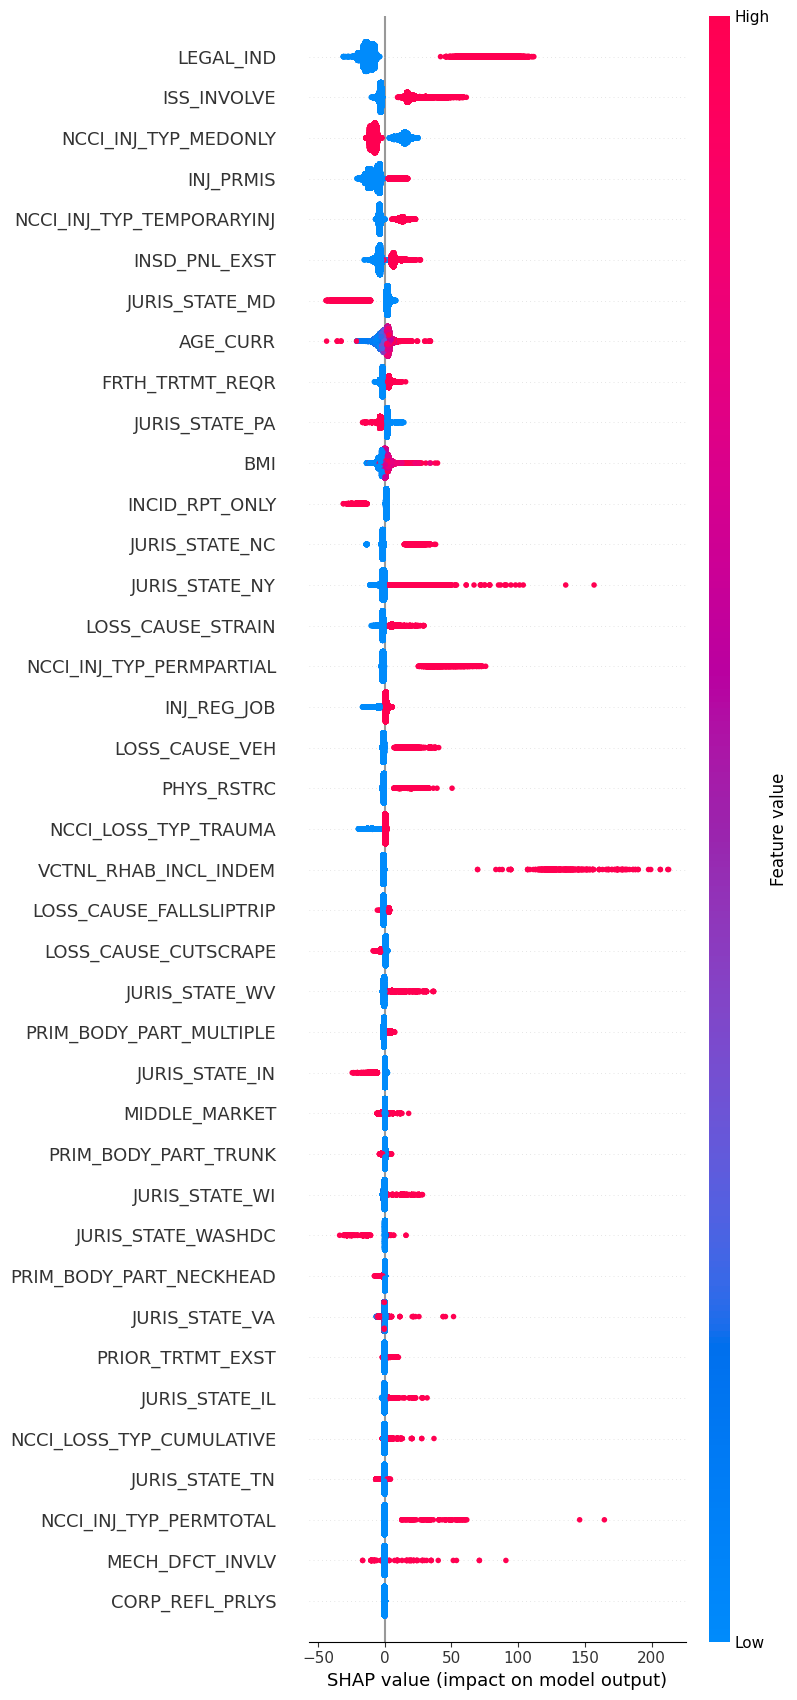

In [21]:
# CREATE A SHAP TREE EXPLAINER FOR THE MODEL
explainer = shap.TreeExplainer(modelh)
# CREATE SHAP VALUES FOR ALL Xs
sValues = explainer.shap_values(x)

# SUMMARIZE SHAP VALUES
shap.summary_plot(sValues,x,max_display=x.shape[1])

In [22]:
# OVERALL MEAN PREDICTIONS - ALL SHAP VALUES DEVIATE FROM THIS
meanPred = explainer.expected_value

In [23]:
# CONVERT SHAP VALUES TO DATAFRAME
shapDf = pd.DataFrame(sValues, columns = [x.columns.tolist()])

# ADD ON MEAN PREDICTION
shapDf['baseline_mean'] = meanPred
shapDf.head()

,AGE_CURR,BMI,FRTH_TRTMT_REQR,INCID_RPT_ONLY,INJ_PRMIS,INJ_REG_JOB,ISS_INVOLVE,JURIS_STATE_PA,JURIS_STATE_VA,JURIS_STATE_MD,JURIS_STATE_NY,JURIS_STATE_WV,JURIS_STATE_WI,JURIS_STATE_NC,JURIS_STATE_TN,JURIS_STATE_IL,JURIS_STATE_IN,JURIS_STATE_WASHDC,LEGAL_IND,LOSS_CAUSE_FALLSLIPTRIP,LOSS_CAUSE_CUTSCRAPE,LOSS_CAUSE_STRAIN,LOSS_CAUSE_VEH,CORP_REFL_PRLYS,INSD_PNL_EXST,PRIOR_TRTMT_EXST,NCCI_INJ_TYP_MEDONLY,NCCI_INJ_TYP_TEMPORARYINJ,NCCI_INJ_TYP_PERMPARTIAL,NCCI_INJ_TYP_PERMTOTAL,NCCI_LOSS_TYP_TRAUMA,NCCI_LOSS_TYP_CUMULATIVE,VCTNL_RHAB_INCL_INDEM,MECH_DFCT_INVLV,PHYS_RSTRC,PRIM_BODY_PART_TRUNK,PRIM_BODY_PART_MULTIPLE,PRIM_BODY_PART_NECKHEAD,MIDDLE_MARKET,baseline_mean
0,11.102212,-6.091046,-1.515784,1.690260,5.413273,-11.517640,-6.969626,-1.687743,0.621120,4.444418,-2.578778,-0.414589,-0.826096,-1.457123,0.120899,-0.053945,0.288331,0.477271,72.855051,2.488492,0.755599,-1.271867,-0.906472,-0.005842,-8.106025,-0.010883,13.230929,13.706232,-0.744301,-0.027083,0.948022,-0.048486,-0.586574,0.012979,-1.325494,0.427954,4.256255,0.250725,0.203409,63.956659
1,4.924378,-1.476456,-1.761131,1.262530,2.778447,-4.178618,-4.152379,-2.276200,0.001167,1.907819,-0.797221,-0.333448,0.028195,-1.499595,-0.039855,-0.039569,0.275662,0.178976,-8.190324,2.732828,0.647988,-1.233148,-0.624934,-0.004863,-3.795942,-0.074541,-6.345079,-4.271728,-0.979082,-0.026913,0.411081,-0.081378,-0.189658,0.003571,-0.662083,-1.208750,-0.513501,0.233947,0.267956,63.956659
2,6.835464,-3.697123,-1.515784,1.420015,3.862298,-10.067480,-6.310181,-1.761081,0.399716,3.686123,-1.988620,-0.323452,-0.114670,-1.592845,0.104244,-0.053945,0.244259,0.410096,79.652512,-0.734984,0.836328,-1.237338,-0.941302,-0.006820,-6.879225,-0.024238,-6.542321,-3.968462,-0.794323,-0.027075,0.558103,-0.048486,-0.754733,0.024302,-0.945272,0.245180,-0.560767,0.250725,0.203409,63.956659
3,6.475339,-4.459033,-1.822435,1.524062,4.329421,-5.699186,-4.748586,-2.349538,0.241086,2.588350,-1.245999,-0.420625,-0.683230,-1.479394,-0.026718,-0.053945,0.280752,0.283021,-12.998654,-0.975297,0.695690,-1.271867,-0.589770,-0.006225,-5.010279,-0.002806,12.655829,15.467896,-0.844774,-0.026921,0.838803,-0.081378,-0.197953,-0.007752,-1.065107,0.366544,4.193813,0.233947,0.267956,63.956659
4,6.848952,-4.622134,-1.871340,1.404865,4.272662,-5.825699,-5.399990,-2.161565,0.241086,2.458462,-1.278023,-0.424793,-0.683230,-1.341858,-0.023200,-0.053945,0.337846,0.259350,-13.217045,-0.812527,0.656884,4.858115,-0.625377,-0.005891,-4.754015,0.033051,12.898060,14.504515,-1.144473,-0.026921,0.838803,-0.081378,-0.723675,-0.007752,-1.036611,-1.971341,-0.601034,0.234309,0.262495,63.956659


In [24]:
# IGNORE INDEX (NEED TO MAINTAIN ROW SORTING INTEGRITY HERE)
scored.reset_index(drop=True, inplace=True)
shapDf.reset_index(drop=True, inplace=True)
# MERGE ON SHAP VALUES
scoredShap = pd.concat([scored,shapDf], axis=1, sort=False)
scoredShap.head(5)

,drpno,pred,"(AGE_CURR,)","(BMI,)","(FRTH_TRTMT_REQR,)","(INCID_RPT_ONLY,)","(INJ_PRMIS,)","(INJ_REG_JOB,)","(ISS_INVOLVE,)","(JURIS_STATE_PA,)","(JURIS_STATE_VA,)","(JURIS_STATE_MD,)","(JURIS_STATE_NY,)","(JURIS_STATE_WV,)","(JURIS_STATE_WI,)","(JURIS_STATE_NC,)","(JURIS_STATE_TN,)","(JURIS_STATE_IL,)","(JURIS_STATE_IN,)","(JURIS_STATE_WASHDC,)","(LEGAL_IND,)","(LOSS_CAUSE_FALLSLIPTRIP,)","(LOSS_CAUSE_CUTSCRAPE,)","(LOSS_CAUSE_STRAIN,)","(LOSS_CAUSE_VEH,)","(CORP_REFL_PRLYS,)","(INSD_PNL_EXST,)","(PRIOR_TRTMT_EXST,)","(NCCI_INJ_TYP_MEDONLY,)","(NCCI_INJ_TYP_TEMPORARYINJ,)","(NCCI_INJ_TYP_PERMPARTIAL,)","(NCCI_INJ_TYP_PERMTOTAL,)","(NCCI_LOSS_TYP_TRAUMA,)","(NCCI_LOSS_TYP_CUMULATIVE,)","(VCTNL_RHAB_INCL_INDEM,)","(MECH_DFCT_INVLV,)","(PHYS_RSTRC,)","(PRIM_BODY_PART_TRUNK,)","(PRIM_BODY_PART_MULTIPLE,)","(PRIM_BODY_PART_NECKHEAD,)","(MIDDLE_MARKET,)","(baseline_mean,)"
0,000100037018-T5726-WC NE-PA-Completed-20220713,151.104695,11.102212,-6.091046,-1.515784,1.690260,5.413273,-11.517640,-6.969626,-1.687743,0.621120,4.444418,-2.578778,-0.414589,-0.826096,-1.457123,0.120899,-0.053945,0.288331,0.477271,72.855051,2.488492,0.755599,-1.271867,-0.906472,-0.005842,-8.106025,-0.010883,13.230929,13.706232,-0.744301,-0.027083,0.948022,-0.048486,-0.586574,0.012979,-1.325494,0.427954,4.256255,0.250725,0.203409,63.956659
1,000100071611-M0745-WC NE-PA-Completed-20240515,34.854809,4.924378,-1.476456,-1.761131,1.262530,2.778447,-4.178618,-4.152379,-2.276200,0.001167,1.907819,-0.797221,-0.333448,0.028195,-1.499595,-0.039855,-0.039569,0.275662,0.178976,-8.190324,2.732828,0.647988,-1.233148,-0.624934,-0.004863,-3.795942,-0.074541,-6.345079,-4.271728,-0.979082,-0.026913,0.411081,-0.081378,-0.189658,0.003571,-0.662083,-1.208750,-0.513501,0.233947,0.267956,63.956659
2,000110190270-M0745-WC NE-PA-Completed-20221019,111.798907,6.835464,-3.697123,-1.515784,1.420015,3.862298,-10.067480,-6.310181,-1.761081,0.399716,3.686123,-1.988620,-0.323452,-0.114670,-1.592845,0.104244,-0.053945,0.244259,0.410096,79.652512,-0.734984,0.836328,-1.237338,-0.941302,-0.006820,-6.879225,-0.024238,-6.542321,-3.968462,-0.794323,-0.027075,0.558103,-0.048486,-0.754733,0.024302,-0.945272,0.245180,-0.560767,0.250725,0.203409,63.956659
3,000110319161-B7419-WC NE-PA-Completed-20220209,68.331697,6.475339,-4.459033,-1.822435,1.524062,4.329421,-5.699186,-4.748586,-2.349538,0.241086,2.588350,-1.245999,-0.420625,-0.683230,-1.479394,-0.026718,-0.053945,0.280752,0.283021,-12.998654,-0.975297,0.695690,-1.271867,-0.589770,-0.006225,-5.010279,-0.002806,12.655829,15.467896,-0.844774,-0.026921,0.838803,-0.081378,-0.197953,-0.007752,-1.065107,0.366544,4.193813,0.233947,0.267956,63.956659
4,000150068865-D209A-WC NE-PA-Completed-20221214,65.372297,6.848952,-4.622134,-1.871340,1.404865,4.272662,-5.825699,-5.399990,-2.161565,0.241086,2.458462,-1.278023,-0.424793,-0.683230,-1.341858,-0.023200,-0.053945,0.337846,0.259350,-13.217045,-0.812527,0.656884,4.858115,-0.625377,-0.005891,-4.754015,0.033051,12.898060,14.504515,-1.144473,-0.026921,0.838803,-0.081378,-0.723675,-0.007752,-1.036611,-1.971341,-0.601034,0.234309,0.262495,63.956659


In [25]:
counter = 0

In [26]:
#counter = counter+1
shap.force_plot(explainer.expected_value, sValues[counter,:], x.iloc[counter,:])

In [27]:
# EXPORT
#scoredShap.to_csv(r'A:\Modeling\Claims\Resource Capacity\Workers Comp Adjuster\Models\Scoring Output\model_shap_' + date + '.csv', index=True)
scoredShap.to_csv(r'A:\Share\Claims\WPC\TESTING 2\Workers Comp\2024\05-29-2024\model_shap_' + date + '.csv', index=True)